Develop advanced multi-dimensional heatmaps using hierarchical clustering and dendrograms to visualize complex relationships and correlation structures within high-dimensional datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
np.random.seed(42)

In [3]:
n_samples = 100
base_signal_1 = np.random.normal(0, 1, n_samples)
base_signal_2 = np.random.normal(5, 2, n_samples)

In [4]:
data = {
    'metric_A1': base_signal_1 + np.random.normal(0, 0.2, n_samples),
    'metric_A2': base_signal_1 * 1.5 + np.random.normal(0, 0.3, n_samples),
    'metric_A3': -base_signal_1 + np.random.normal(0, 0.2, n_samples),
    'metric_B1': base_signal_2 + np.random.normal(0, 0.4, n_samples),
    'metric_B2': base_signal_2 * 0.8 + np.random.normal(0, 0.5, n_samples),
    'metric_B3': base_signal_2 * 2.0 + np.random.normal(0, 0.3, n_samples),
    'metric_C1': np.random.uniform(10, 50, n_samples),
    'metric_C2': np.random.uniform(0, 1, n_samples),
    'metric_D1': np.random.normal(100, 15, n_samples),
    'metric_D2': np.random.normal(105, 12, n_samples),
}

df_multidim = pd.DataFrame(data)

In [5]:
print(df_multidim.head())

   metric_A1  metric_A2  metric_A3  metric_B1  metric_B2  metric_B3  \
0   0.568272   0.496373  -0.815600   2.539730   2.113901   4.181700   
1  -0.026107  -0.375451   0.018389   4.922476   2.865885   8.632121   
2   0.864299   1.195721  -0.646640   3.755144   3.886460   8.417839   
3   1.733790   2.467656  -1.513634   3.620633   3.394175   6.368353   
4  -0.509687  -0.357501   0.144140   4.417172   3.948660   8.887868   

   metric_C1  metric_C2   metric_D1   metric_D2  
0  22.764019   0.372689   99.316210  122.718484  
1  43.156619   0.259754  103.650092  121.561096  
2  11.480305   0.723420   96.381459   97.493248  
3  33.850795   0.495876  105.280831  109.749642  
4  19.200353   0.081046   81.226909  110.928362  


In [6]:
corr_matrix = df_multidim.corr()

In [7]:
df_standardized = (df_multidim - df_multidim.mean()) / df_multidim.std()

In [8]:
print("Correlation Matrix dimensions:", corr_matrix.shape)
print("Standardized Matrix summary stats:")
print(df_standardized.describe().loc[['mean', 'std']].round(2))

Correlation Matrix dimensions: (10, 10)
Standardized Matrix summary stats:
      metric_A1  metric_A2  metric_A3  metric_B1  metric_B2  metric_B3  \
mean        0.0        0.0        0.0       -0.0        0.0       -0.0   
std         1.0        1.0        1.0        1.0        1.0        1.0   

      metric_C1  metric_C2  metric_D1  metric_D2  
mean        0.0        0.0       -0.0        0.0  
std         1.0        1.0        1.0        1.0  


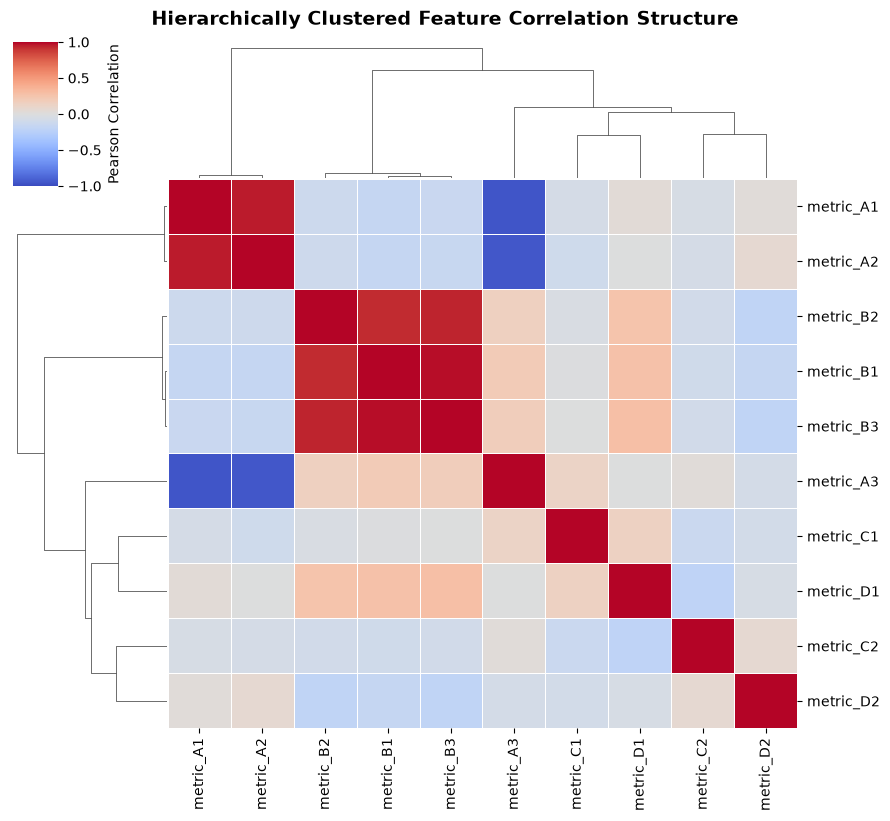

In [11]:
cluster_corr = sns.clustermap(
    corr_matrix,
    method='ward',
    metric='euclidean',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    annot=False,          # Correct parameter name
    linewidths=0.5,
    figsize=(9, 8),
    cbar_kws={'label': 'Pearson Correlation'}
)

cluster_corr.fig.suptitle(
    'Hierarchically Clustered Feature Correlation Structure', 
    fontsize=14, 
    fontweight='bold', 
    y=1.02
)
plt.show()

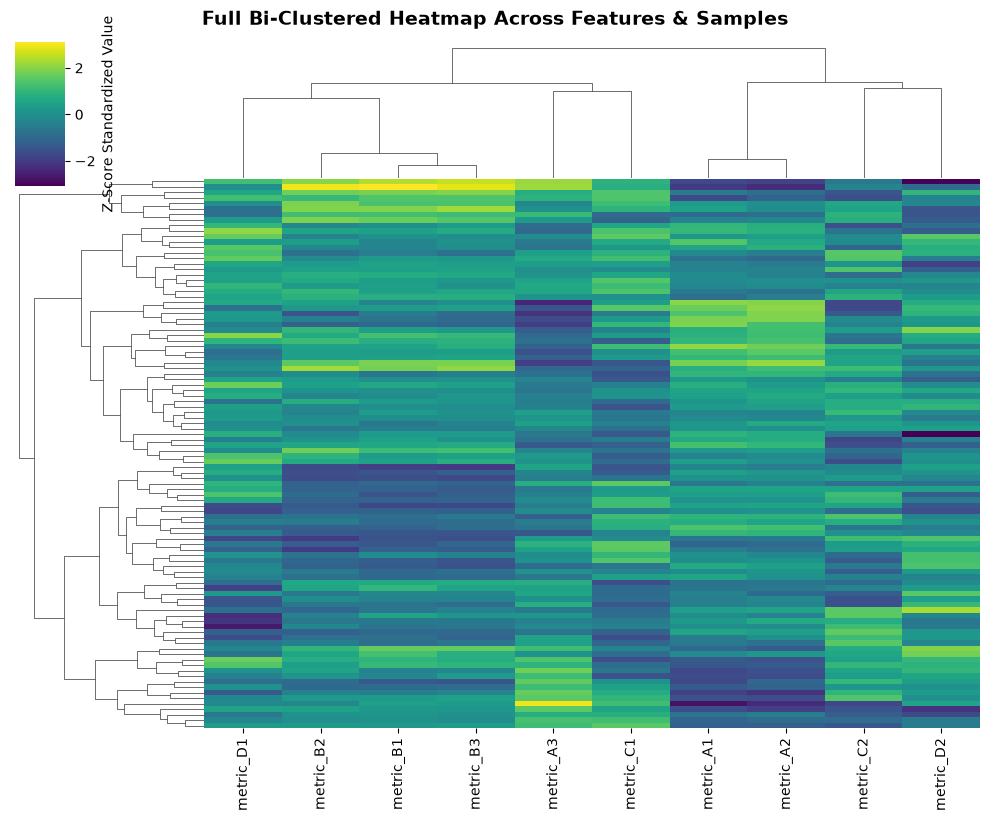

In [13]:
bicluster_grid = sns.clustermap(
    df_standardized,
    method='complete',
    metric='euclidean',
    cmap='viridis',
    col_cluster=True,
    row_cluster=True,
    yticklabels=False,
    xticklabels=True,
    figsize=(10, 8),
    cbar_kws={'label': 'Z-Score Standardized Value'}
)
bicluster_grid.fig.suptitle(
    'Full Bi-Clustered Heatmap Across Features & Samples', 
    fontsize=14, 
    fontweight='bold', 
    y=1.02
)
plt.show()

In [14]:
reordered_col_indices = bicluster_grid.dendrogram_col.reordered_ind
reordered_features = df_multidim.columns[reordered_col_indices].tolist()

In [16]:
print("Hierarchical Feature Ordering")
print("Original Feature Order:", df_multidim.columns.tolist())
print("Hierarchically Clustered Order:", reordered_features)

Hierarchical Feature Ordering
Original Feature Order: ['metric_A1', 'metric_A2', 'metric_A3', 'metric_B1', 'metric_B2', 'metric_B3', 'metric_C1', 'metric_C2', 'metric_D1', 'metric_D2']
Hierarchically Clustered Order: ['metric_D1', 'metric_B2', 'metric_B1', 'metric_B3', 'metric_A3', 'metric_C1', 'metric_A1', 'metric_A2', 'metric_C2', 'metric_D2']
